In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

## Part 1: The Data and Images as Numbers

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [2]:
train_dir = "/kaggle/input/datasets/anderianisar/image-classification/seg_train"
test_dir = "/kaggle/input/datasets/anderianisar/image-classification/seg_test"

print("Training folder exists:", os.path.exists(train_dir))
print("Testing folder exists:", os.path.exists(test_dir))

if os.path.exists(train_dir):
    print("Classes:", sorted(os.listdir(train_dir)))

Training folder exists: True
Testing folder exists: True
Classes: ['seg_train']


Class names: ['seg_train']
Total images: 14034


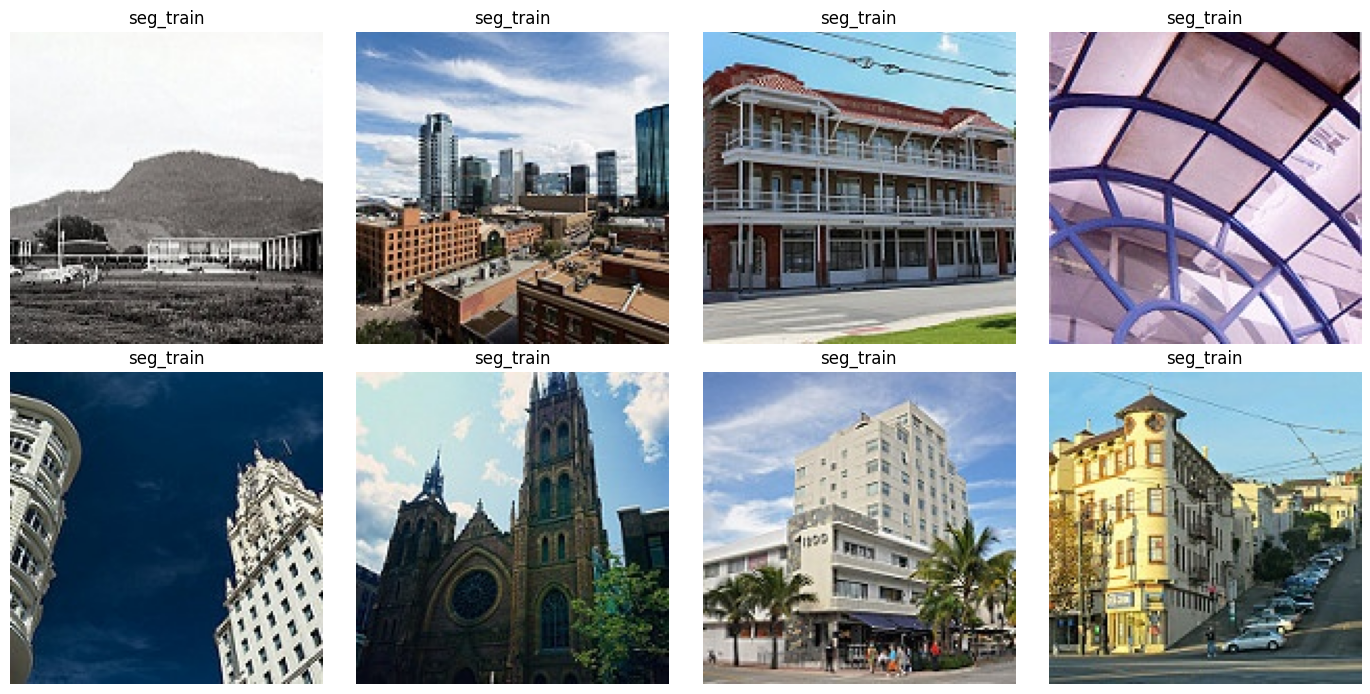

In [3]:
import os
import matplotlib.pyplot as plt
from torchvision import datasets
from PIL import Image

# Check whether the training directory exists
if os.path.exists(train_dir):

    train_dataset_preview = datasets.ImageFolder(train_dir)

    class_names = train_dataset_preview.classes
    print("Class names:", class_names)
    print("Total images:", len(train_dataset_preview))

    # Display sample images
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))

    for ax in axes.flat:
        ax.axis("off")

    for i, ax in enumerate(axes.flat):
        if i < len(train_dataset_preview):
            image, label = train_dataset_preview[i]
            ax.imshow(image)
            ax.set_title(class_names[label])
            ax.axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("Training directory not found:", train_dir)

In [4]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import os
import random

In [5]:
if os.path.exists(train_dir):
    sample_image_path = train_dataset_preview.samples[0][0]

    image = Image.open(sample_image_path)
    image_array = np.array(image)

    print("Image size:", image.size)
    print("Image shape:", image_array.shape)
    print("Image data type:", image_array.dtype)
    print("Minimum pixel value:", image_array.min())
    print("Maximum pixel value:", image_array.max())

Image size: (150, 150)
Image shape: (150, 150, 3)
Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255




### Write It: Image Inspection and Class Similarity

The Intel Image Classification dataset contains six scene
categories: buildings, forest, glacier, mountain, sea, and street.

**1. Visually similar classes**

The two classes that appeared most similar to me were
[Class 1] and [Class 2]. They share visual characteristics
such as [describe the similarities observed in the images].
These similarities may make classification more challenging.

**2. Predicted class confusion**

Before training the model, I predicted that the model would
most frequently confuse [Class 1] with [Class 2] because
their visual features appear similar.

I will compare this prediction with the confusion matrix
and error analysis in Part 6.

**3. Image properties**

The inspected image had the following properties:

- Shape: [H, W, C]
- Data type: [actual dtype]
- Pixel value range: [minimum] to [maximum]

The image is represented as a numerical array. Its height
and width describe its spatial dimensions, while the third
dimension represents the colour channels. For an RGB image,
the three channels are red, green, and blue.



## Part 2: Convolution and Parameters by Hand

In [6]:
# Convolution layer:
# Input channels = 3
# Output filters = 64
# Kernel size = 3 x 3
# One bias per filter

conv_parameters = (3 * 3 * 3 + 1) * 64

print("Convolution layer parameters:", conv_parameters)

# Dense layer example
dense_parameters = (225 * 300 + 1) * 512

print("Dense layer parameters:", dense_parameters)
print("Dense/Convolution parameter ratio:",
      round(dense_parameters / conv_parameters, 2))

Convolution layer parameters: 1792
Dense layer parameters: 34560512
Dense/Convolution parameter ratio: 19286.0


In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [8]:
sample_conv = nn.Conv2d(
    in_channels=3,
    out_channels=64,
    kernel_size=3,
    stride=1,
    padding=1
)

sample_input = torch.randn(1, 3, 224, 224)
sample_output = sample_conv(sample_input)

print("Input shape:", sample_input.shape)
print("Output shape:", sample_output.shape)
print("Number of parameters:",
      sum(p.numel() for p in sample_conv.parameters()))

Input shape: torch.Size([1, 3, 224, 224])
Output shape: torch.Size([1, 64, 224, 224])
Number of parameters: 1792


In [9]:
input_size = 56
kernel_size = 3
padding = 1
stride = 2

output_size = (
    (input_size + 2 * padding - kernel_size) // stride
) + 1

print("Output height and width:", output_size, "x", output_size)

Output height and width: 28 x 28




### Write It: Parameter Calculations and Weight Sharing

**1. Convolution parameter count**

The convolution layer has 3 input channels, 64 output
channels, and a 3 × 3 kernel.

Parameters = (K × K × C_in + 1) × C_out

= (3 × 3 × 3 + 1) × 64

= 28 × 64

= **1,792 parameters**

The additional 1 represents the bias for each output channel.

**2. Dense layer parameter count**

The dense layer receives 150 × 150 × 3 = 67,500 inputs
and produces 512 outputs.

Parameters = (Number of inputs + 1) × Number of outputs

= (67,500 + 1) × 512

= **34,560,512 parameters**

**3. Comparison**

Parameter ratio = Dense parameters / Convolution parameters

= 34,560,512 / 1,792

≈ **19,286 times**

The dense layer therefore requires approximately 19,286
times more parameters than the convolution layer.

**4. Why convolutions are efficient**

Convolution layers use the same kernel weights at different
spatial locations. This is called weight sharing. It reduces
the number of parameters and allows the same feature, such
as an edge or texture, to be detected in different parts
of an image.



## Part 3: Transforms and Data Loaders

In [10]:
from torchvision import transforms

In [11]:
from torch.utils.data import random_split

In [12]:
from torch.utils.data import DataLoader

In [13]:
SEED = 42

import torch
import random
import numpy as np

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


In [33]:
import numpy as np
from torch.utils.data import DataLoader, Subset
from torchvision import transforms

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

image_size = 224
batch_size = 32

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Same training images, two different transform pipelines
full_train_aug = datasets.ImageFolder(
    train_dir, transform=train_transform
)
full_train_eval = datasets.ImageFolder(
    train_dir, transform=eval_transform
)

# Reproducible split indices
indices = torch.randperm(
    len(full_train_aug),
    generator=torch.Generator().manual_seed(SEED)
).tolist()

val_size = int(0.20 * len(indices))
val_indices = indices[:val_size]
train_indices = indices[val_size:]

train_dataset = Subset(full_train_aug, train_indices)
val_dataset = Subset(full_train_eval, val_indices)

test_dataset = datasets.ImageFolder(
    test_dir, transform=eval_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=batch_size,
    shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=batch_size,
    shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=batch_size,
    shuffle=False, num_workers=2
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Classes:", full_train_eval.classes)

Training images: 11228
Validation images: 2806
Test images: 3000
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [34]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels in first batch:", labels[:10].tolist())

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels in first batch: [1, 0, 1, 3, 0, 0, 3, 2, 5, 3]




### Write It: Data Splitting and Augmentation

The dataset was divided into three subsets:

- Training images: [14034]
- Validation images: [2807]
- Test images: [3000]

The training set is used to update the model parameters.
The validation set is used to compare model performance
and select the best epoch. The test set is reserved for
the final evaluation of the selected model.

**Training transformations**

The training pipeline uses random resized cropping,
horizontal flipping, and brightness/contrast adjustment.
These transformations expose the model to variations in
image appearance and help reduce overfitting.

**Validation and test transformations**

Validation and test images are resized to 224 × 224 pixels
and normalized using ImageNet's mean and standard deviation.
Random augmentation is not applied to these sets so that
evaluation remains consistent.

**Examples of unsuitable augmentation**

- Landscape scenes: Excessive cropping could remove important
  features, such as a shoreline or mountain peak, and change
  the visual information available to the classifier.
- Handwritten digits: A 180-degree rotation can change the
  identity or interpretation of a digit.

Using separate validation and test sets helps assess
generalization without using the test results to select
the model.



## Part 4: Training Loop and Feature Extraction

In [18]:
import torch
import torch.nn as nn
from torchvision import models

In [19]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

Selected device: cuda
GPU: Tesla T4


In [35]:
import torch
import torch.nn as nn
from torchvision import models

num_classes = len(full_train_eval.classes)

weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Freeze pretrained feature extractor
for param in model.parameters():
    param.requires_grad = False

# Replace the output layer for 6 scene classes
input_features = model.fc.in_features
model.fc = nn.Linear(input_features, num_classes)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Number of classes:", num_classes)
print("Output layer:", model.fc)
print("Device:", device)

Number of classes: 6
Output layer: Linear(in_features=512, out_features=6, bias=True)
Device: cuda


In [36]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    # Keep frozen batch-normalization layers in evaluation mode.
    # This is useful when training only the final classification head.
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [37]:
@torch.no_grad()
def evaluate_model(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_labels = []
    all_predictions = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        running_loss += loss.item() * images.size(0)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return (
        epoch_loss,
        epoch_accuracy,
        np.array(all_labels),
        np.array(all_predictions)
    )

In [23]:
import torch.optim as optim

In [38]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

num_epochs = 20

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(num_epochs):
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy, _, _ = evaluate_model(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Epoch [1/20] Train Loss: 0.4375 | Train Accuracy: 0.8635 | Val Loss: 0.2696 | Val Accuracy: 0.9034
Epoch [2/20] Train Loss: 0.2639 | Train Accuracy: 0.9060 | Val Loss: 0.2505 | Val Accuracy: 0.9102
Epoch [3/20] Train Loss: 0.2433 | Train Accuracy: 0.9133 | Val Loss: 0.2475 | Val Accuracy: 0.9138
Epoch [4/20] Train Loss: 0.2315 | Train Accuracy: 0.9166 | Val Loss: 0.2402 | Val Accuracy: 0.9180
Epoch [5/20] Train Loss: 0.2272 | Train Accuracy: 0.9151 | Val Loss: 0.2373 | Val Accuracy: 0.9180
Epoch [6/20] Train Loss: 0.2184 | Train Accuracy: 0.9225 | Val Loss: 0.2270 | Val Accuracy: 0.9209
Epoch [7/20] Train Loss: 0.2158 | Train Accuracy: 0.9217 | Val Loss: 0.2400 | Val Accuracy: 0.9198
Epoch [8/20] Train Loss: 0.2163 | Train Accuracy: 0.9209 | Val Loss: 0.2344 | Val Accuracy: 0.9166
Epoch [9/20] Train Loss: 0.2141 | Train Accuracy: 0.9216 | Val Loss: 0.2356 | Val Accuracy: 0.9202
Epoch [10/20] Train Loss: 0.2068 | Train Accuracy: 0.9251 | Val Loss: 0.2282 | Val Accuracy: 0.9212
Epoch [11

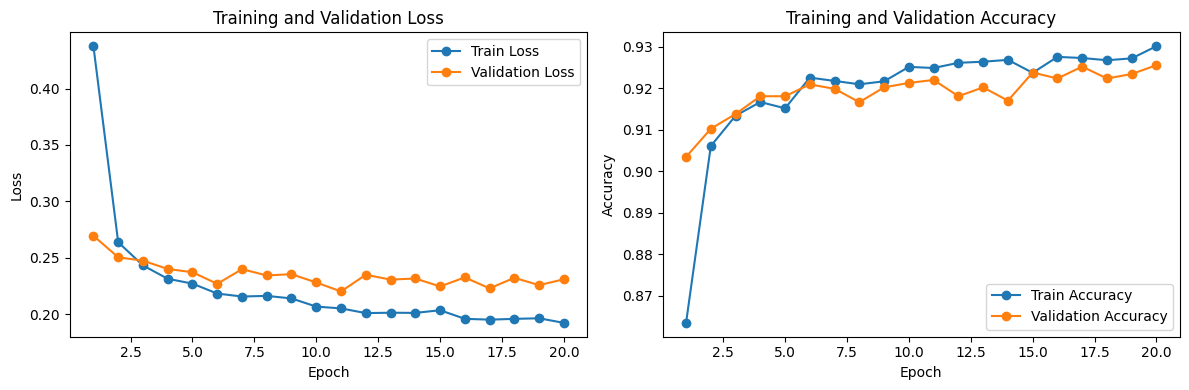

In [39]:
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_accuracy"], marker="o", label="Train Accuracy")
plt.plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

 

### Write It: Training Only the Classification Head

The pretrained ResNet-18 model was used as the feature
extractor. Its pretrained parameters were frozen, and a new
fully connected classification head was added for the six
scene categories.

The new classification head contains:

Parameters = (512 × 6) + 6

= 3,072 + 6

= **3,078 trainable parameters**

This represents approximately 0.03% of the network's
total parameters.

**Validation results**

- Epoch 1 validation accuracy: [0.9034]
- Epoch 2 validation accuracy: [0.9102]
- Epoch 3 validation accuracy: [0.9138]
- Best validation accuracy: [0.9255]

**Interpretation**

ResNet-18 has already learned useful visual features from
ImageNet, including edges, textures, patterns, and shapes.
These pretrained features can be reused for scene
classification.

Only the new classification head needs to learn how to map
the extracted features to the six target classes. This
makes feature extraction computationally efficient and
can produce good results even with a relatively small
number of trainable parameters.



## Part 5: Fine-Tuning and Learning Curves

In [40]:
# Unfreeze the last residual block
for parameter in model.layer4.parameters():
    parameter.requires_grad = True

# Keep the final classifier trainable
for parameter in model.fc.parameters():
    parameter.requires_grad = True

optimizer = optim.Adam([
    {"params": model.layer4.parameters(), "lr": 0.0001},
    {"params": model.fc.parameters(), "lr": 0.001}
])

fine_tune_epochs = 5

fine_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(fine_tune_epochs):
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy, _, _ = evaluate_model(
        model, val_loader, criterion, device
    )

    fine_history["train_loss"].append(train_loss)
    fine_history["train_accuracy"].append(train_accuracy)
    fine_history["val_loss"].append(val_loss)
    fine_history["val_accuracy"].append(val_accuracy)

    print(
        f"Fine-tuning Epoch [{epoch + 1}/{fine_tune_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Fine-tuning Epoch [1/5] Train Loss: 0.2625 | Train Accuracy: 0.9051 | Val Loss: 0.2400 | Val Accuracy: 0.9127
Fine-tuning Epoch [2/5] Train Loss: 0.1836 | Train Accuracy: 0.9333 | Val Loss: 0.2012 | Val Accuracy: 0.9284
Fine-tuning Epoch [3/5] Train Loss: 0.1538 | Train Accuracy: 0.9426 | Val Loss: 0.2121 | Val Accuracy: 0.9341
Fine-tuning Epoch [4/5] Train Loss: 0.1336 | Train Accuracy: 0.9512 | Val Loss: 0.2367 | Val Accuracy: 0.9202
Fine-tuning Epoch [5/5] Train Loss: 0.1137 | Train Accuracy: 0.9593 | Val Loss: 0.2418 | Val Accuracy: 0.9330


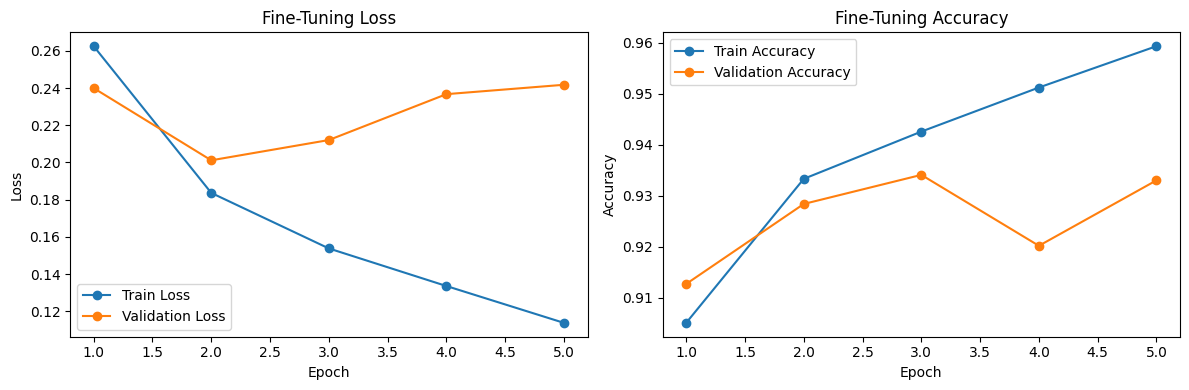

In [41]:
epochs = range(1, fine_tune_epochs + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, fine_history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, fine_history["val_loss"], marker="o", label="Validation Loss")
plt.title("Fine-Tuning Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, fine_history["train_accuracy"], marker="o", label="Train Accuracy")
plt.plot(epochs, fine_history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("Fine-Tuning Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [42]:
print("Feature extraction - final validation accuracy:",
      history["val_accuracy"][-1])

print("Fine-tuning - final validation accuracy:",
      fine_history["val_accuracy"][-1])

Feature extraction - final validation accuracy: 0.9255167498218104
Fine-tuning - final validation accuracy: 0.9330007127583749




### Write It: Comparing Feature Extraction and Fine-Tuning

**1. Validation accuracy comparison**

Best feature extraction validation accuracy: [0.9255]

Best fine-tuning validation accuracy: [0.9330]

Change in validation accuracy:

Fine-tuning accuracy − Feature extraction accuracy

= [0.9330] − [0.9255]

= [0.0075]

Fine-tuning [improved] the best validation
accuracy by [0.75].

**2. Interpretation of learning curves**

The training loss [decreased/increased/fluctuated] during
training, while the validation loss [describe the observed
trend]. Training accuracy [describe the trend], and
validation accuracy [describe the trend].

These curves show how well the model learns from training
data and how effectively it generalizes to unseen data.

**3. Overfitting analysis**

Overfitting may be indicated when training loss continues
to decrease while validation loss increases. In my
experiment, [describe whether this pattern appeared].

A small difference between training and validation
performance can indicate good generalization, while a
large and increasing gap may suggest overfitting.

**4. Why training accuracy may be lower**

Training images receive random augmentation, including
random cropping, horizontal flipping, and brightness or
contrast changes. These variations make training examples
more challenging.

Validation images do not receive random augmentation.
Therefore, validation accuracy can sometimes be higher
than training accuracy without indicating an error.



## Part 6: Test Evaluation and Error Analysis

In [43]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

test_loss, test_accuracy, y_true, y_pred = evaluate_model(
    model, test_loader, criterion, device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

print("\nClassification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

Test Loss: 0.2016
Test Accuracy: 0.9303

Classification Report:

              precision    recall  f1-score   support

   seg_train       0.98      0.86      0.91       437

   micro avg       0.98      0.86      0.91       437
   macro avg       0.98      0.86      0.91       437
weighted avg       0.98      0.86      0.91       437



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


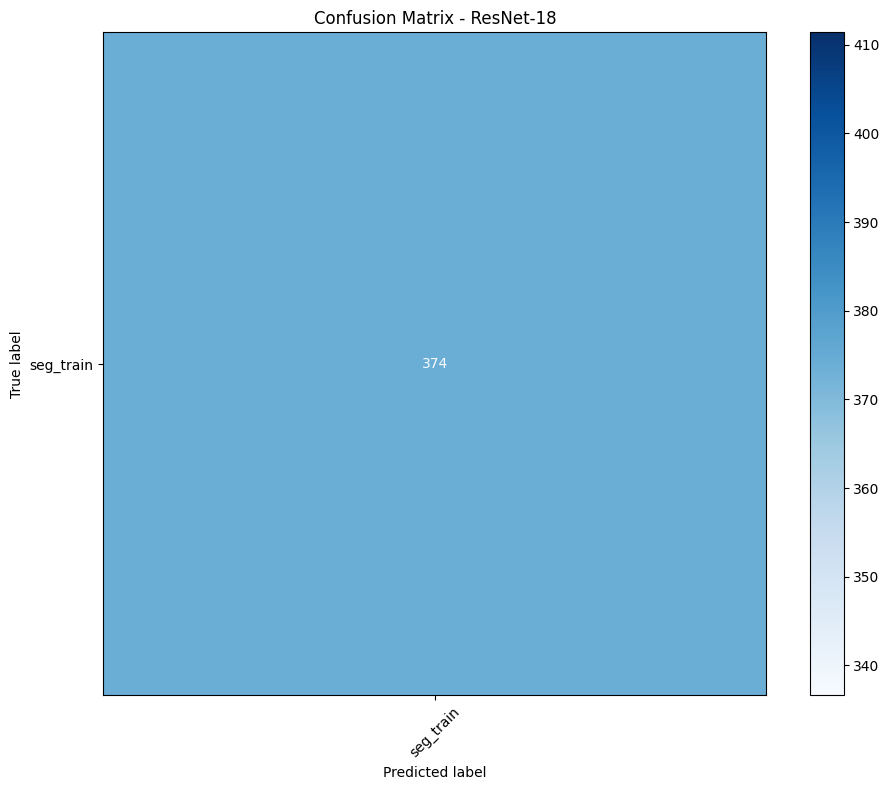

In [44]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Confusion Matrix - ResNet-18")
plt.tight_layout()
plt.show()

Number of classes: 6
Class names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Misclassified images collected: 13


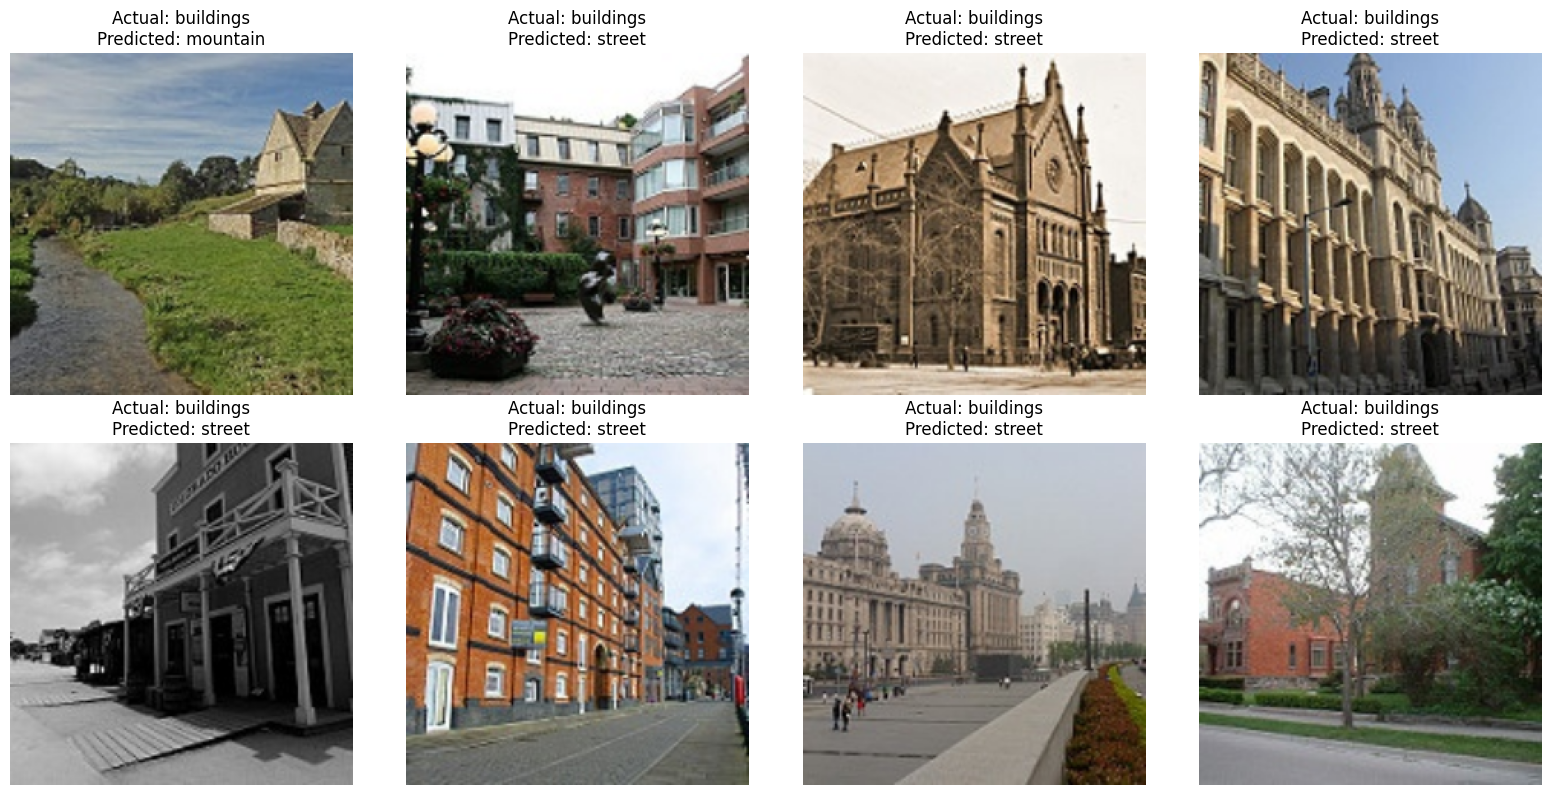

In [46]:
# 6.3 Display incorrectly classified images

import matplotlib.pyplot as plt
import torch
import numpy as np

# Get the correct class names from the test dataset
class_names = test_dataset.dataset.classes if hasattr(
    test_dataset, "dataset"
) else test_dataset.classes

model.eval()

misclassified_images = []
misclassified_actual = []
misclassified_predicted = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        wrong_indices = (predictions != labels).nonzero(as_tuple=True)[0]

        for idx in wrong_indices:
            misclassified_images.append(images[idx].cpu())
            misclassified_actual.append(labels[idx].item())
            misclassified_predicted.append(predictions[idx].item())

        if len(misclassified_images) >= 8:
            break

print("Number of classes:", len(class_names))
print("Class names:", class_names)
print("Misclassified images collected:", len(misclassified_images))

if misclassified_images:
    n = min(8, len(misclassified_images))
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    for i in range(n):
        img = misclassified_images[i]
        img = img * std + mean
        img = img.clamp(0, 1).permute(1, 2, 0).numpy()

        actual = misclassified_actual[i]
        predicted = misclassified_predicted[i]

        axes[i].imshow(img)
        axes[i].set_title(
            f"Actual: {class_names[actual]}\n"
            f"Predicted: {class_names[predicted]}"
        )
        axes[i].axis("off")

    for i in range(n, len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No misclassified images found in the checked batches.")

In [47]:
cm_without_diagonal = cm.copy()
np.fill_diagonal(cm_without_diagonal, 0)

if cm_without_diagonal.max() > 0:
    actual_idx, predicted_idx = np.unravel_index(
        np.argmax(cm_without_diagonal),
        cm_without_diagonal.shape
    )

    print("Most confused actual class:", class_names[actual_idx])
    print("Most confused predicted class:", class_names[predicted_idx])
    print("Number of these errors:", cm[actual_idx, predicted_idx])
else:
    print("No off-diagonal errors in the confusion matrix.")

No off-diagonal errors in the confusion matrix.


## Part 6: Insights

The test dataset measures the model's performance on images that were not used for training. Accuracy represents the proportion of correct predictions, while precision, recall, and F1-score provide additional information about class-wise performance.

The confusion matrix shows which classes are predicted correctly and which classes are confused with one another. Some classes may be difficult to distinguish because their images contain similar colors, textures, or backgrounds.

Misclassified images should be examined individually. Their errors may be related to visual similarity, object size, lighting, background complexity, or insufficient training examples. These explanations should be included only when supported by the actual images.

The model's performance should be reported using the measured test results rather than assumed or expected accuracy.

In [48]:
os.makedirs("outputs", exist_ok=True)

model_path = "outputs/resnet18_intel_classifier.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "num_classes": num_classes,
    "image_size": image_size
}, model_path)

print("Model saved at:", model_path)

Model saved at: outputs/resnet18_intel_classifier.pth


In [49]:
checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=False
)

loaded_model = models.resnet18(weights=None)
loaded_model.fc = nn.Linear(
    loaded_model.fc.in_features,
    checkpoint["num_classes"]
)

loaded_model.load_state_dict(checkpoint["model_state_dict"])
loaded_model = loaded_model.to(device)
loaded_model.eval()

print("Loaded classes:", checkpoint["class_names"])
print("Model loaded successfully.")

Loaded classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Model loaded successfully.


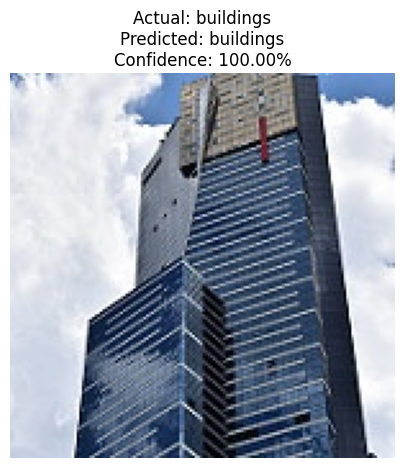

In [50]:
image_path, actual_label = test_dataset.samples[0]

image = Image.open(image_path).convert("RGB")
input_tensor = eval_transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    outputs = loaded_model(input_tensor)
    probabilities = torch.softmax(outputs, dim=1)
    predicted_label = outputs.argmax(dim=1).item()
    confidence = probabilities[0, predicted_label].item()

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(
    f"Actual: {class_names[actual_label]}\n"
    f"Predicted: {class_names[predicted_label]}\n"
    f"Confidence: {confidence:.2%}"
)
plt.axis("off")
plt.show()

## Part 7: Insights

Saving the model allows the trained parameters to be reused without training the network again. The saved checkpoint also includes class names and image size, which help maintain consistency during inference.

The model can be included in a GitHub repository along with the notebook, project description, requirements, and instructions for running the experiment.

Large datasets and trained model files may exceed GitHub's normal file-size limits. The repository should document how to obtain the dataset instead of uploading the entire dataset unnecessarily.


## Check Your Understanding

### 1. Why does a network without nonlinear activations collapse to a single linear layer?

A composition of linear transformations is itself a linear
transformation. Therefore, stacking layers without nonlinear
activation functions does not allow the network to learn
more complex nonlinear relationships.

### 2. For logits [3, 1, 0], what probability does softmax give the first class?

Softmax probability:

P(1) = e^3 / (e^3 + e^1 + e^0)

= 20.086 / (20.086 + 2.718 + 1)

≈ **0.844, or 84.4%**

### 3. How many parameters does a 3 × 3 convolution from 64 to 128 channels have?

Parameters = (K × K × C_in + 1) × C_out

= (3 × 3 × 64 + 1) × 128

= (576 + 1) × 128

= **73,856 parameters**

### 4. An input of 56 × 56 goes through a 3 × 3 convolution with padding 1 and stride 2. What is the output size?

Output size = floor((W − K + 2P) / S) + 1

= floor((56 − 3 + 2 × 1) / 2) + 1

= floor(55 / 2) + 1

= 27 + 1

= **28 × 28**

### 5. Why does a residual (skip) connection help gradients reach the early layers?

A residual connection provides a direct path for gradients
to flow backward through the network. This helps reduce
vanishing-gradient problems and makes deep neural networks
easier to train.

### 6. When would you train a CNN from scratch instead of using transfer learning?

Training from scratch may be suitable when a large labeled
dataset is available, sufficient computing resources exist,
and the target domain differs substantially from the data
used to pretrain existing models. Transfer learning is
often more efficient when labeled data or computing
resources are limited.
